## Assignment 3: $k$ Nearest Neighbor


**Q1.**
1. What is the difference between regression and classification?
2. What is a confusion table? What does it help us understand about a model's performance?
3. What does the SSE quantify about a particular model?
4. What are overfitting and underfitting?
5. Why does splitting the data into training and testing sets, and choosing $k$ by evaluating accuracy or SSE on the test set, improve model performance?
6. With classification, we can report a class label as a prediction or a probability distribution over class labels. Please explain the strengths and weaknesses of each approach.

**Q2.** This is a case study on $k$ nearest neighbor classification, using the `land_mines.csv` data.

The data consists of a label, `mine_type`, taking integer values 1 to 5, and three properties of the mine, `voltage`, `height` and `soil`. We want to predict the kind of mine from data about it. Imagine working for the DOD or a humanitarian aid agency, trying to help people remove land mines more safely.

1. Load the data. Perform some EDA, summarizing the target label and the features.
2. Split the sample 50/50 into training and test/validation sets. (The smaller the data are, the more equal the split should be, in my experience: Otherwise, all of the members of one class end up in the training or test data, and the model falls apart.)
3. Build a $k$-NN classifier. Explain how you select $k$.
4. Print a confusion table for the optimal model, comparing predicted and actual class label on the test set. How accurate is it? Where is performance more or less accurate?
5. Notice that you can have a lot of accurate predictions for a given type of mine, but still make a lot of mistakes. Please explain how you'd advise someone to actually use this predictive model in practice, given the errors that it tends to make.

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [To be provided]

**Date:** [To be provided]

In [ ]:
# Your Phase 1 solution to the problem goes here.


1. Regression predicts a continuous number on a scale (e.g. home price) while classification predicts a category or label from a pre-determined set (e.g. spam email vs. non-spam email)

2. It is a table that shows a model's predictions vs. what the true or correct answer should be. This way we know not just how often a model is right or wrong, but in what ways does it tend to be right or wrong (e.g. false positives vs. false negatives)

3. SSE (sum of squared errors) quantifies how much of the variation in the actual dataset is not being properly accounted for by a regression model. Squaring the errors also makes it such that positive/negative results don't cancel each other out, and bigger errors are exponentially more penalized than small ones.

4. Underfitting happens when the model is too simple to understand the relationships that go on in a dataset, including sometimes the very data its being trained on. Overfitting is the opposite, when the model is too heavily dependent on the training dataset, that it mistakes the random noise or eccentricities of a dataset for the actual relationship being investigated.

5. Splitting the data improves performance because it lets you select k based on generalization rather than memorization. After its done training, you can test the model on the dataset you set aside to accurately gauge performance

6. Using class labels is strong because it is simple and actionable, but it a key weakness is that it hides uncertainty. A barely confident prediction is treated the same as a certain one. Probability distributions are the opposite, they can be a challenge to adequately process or interpret, but doing so properly allows you to have much more nuance and control over the model's output.


--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 338 entries, 0 to 337
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   voltage    338 non-null    float64
 1   height     338 non-null    float64
 2   soil       338 non-null    float64
 3   mine_type  338 non-null    int64  
dtypes: float64(3), int64(1)
memory usage: 10.7 KB
None

--- Descriptive Statistics ---
          voltage      height        soil   mine_type
count  338.000000  338.000000  338.000000  338.000000
mean     0.430634    0.508876    0.503550    2.952663
std      0.195819    0.306043    0.344244    1.419703
min      0.197734    0.000000    0.000000    1.000000
25%      0.309737    0.272727    0.200000    2.000000
50%      0.359516    0.545455    0.600000    3.000000
75%      0.482628    0.727273    0.800000    4.000000
max      0.999999    1.000000    1.000000    5.000000

--- Target Label ('mine_type') Distribution ---
mine_type
1 

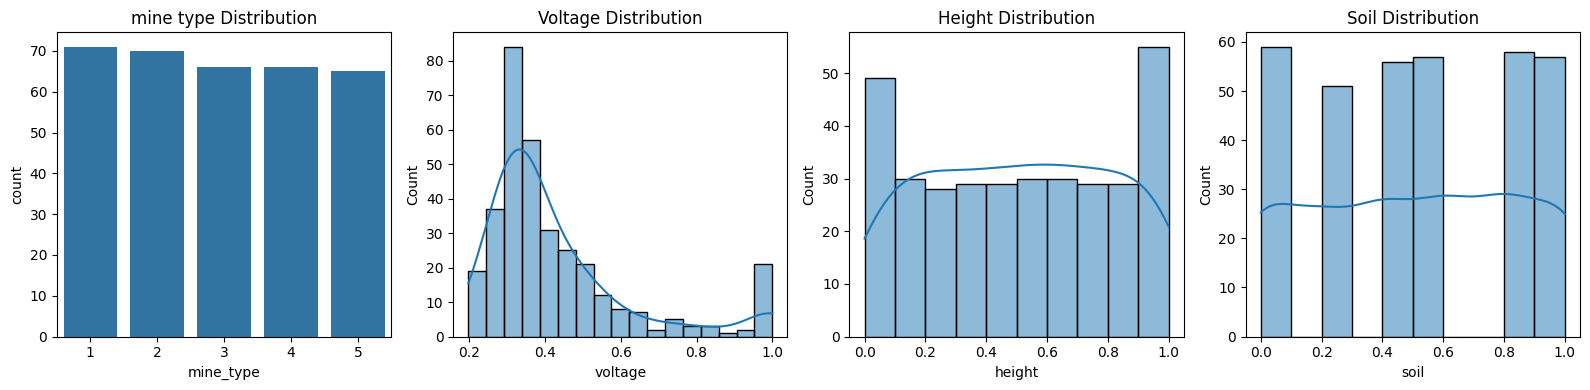

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/land_mines.csv')
print("--- Dataset Info ---")
print(df.info())
print("\n--- Descriptive Statistics ---")
print(df.describe())
print("\n--- Target Label ('mine_type') Distribution ---")
print(df['mine_type'].value_counts().sort_index())


fig, axes = plt.subplots(1, 4, figsize=(16, 4))
sns.countplot(data=df, x='mine_type', ax=axes[0])
axes[0].set_title('mine type Distribution')
sns.histplot(data=df, x='voltage', kde=True, ax=axes[1])
axes[1].set_title('Voltage Distribution')

sns.histplot(data=df, x='height', kde=True, ax=axes[2])
axes[2].set_title('Height Distribution')

sns.histplot(data=df, x='soil', kde=True, ax=axes[3])
axes[3].set_title('Soil Distribution')

plt.tight_layout()
plt.show()

In [6]:
from sklearn.model_selection import train_test_split

X = df[['voltage', 'height', 'soil']]
y = df['mine_type']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.5, random_state=42, stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")
print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())
print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())

Training set shape: (169, 3)
Test set shape: (169, 3)

Training class distribution:
mine_type
1    35
2    35
3    33
4    33
5    33
Name: count, dtype: int64

Testing class distribution:
mine_type
1    36
2    35
3    33
4    33
5    32
Name: count, dtype: int64


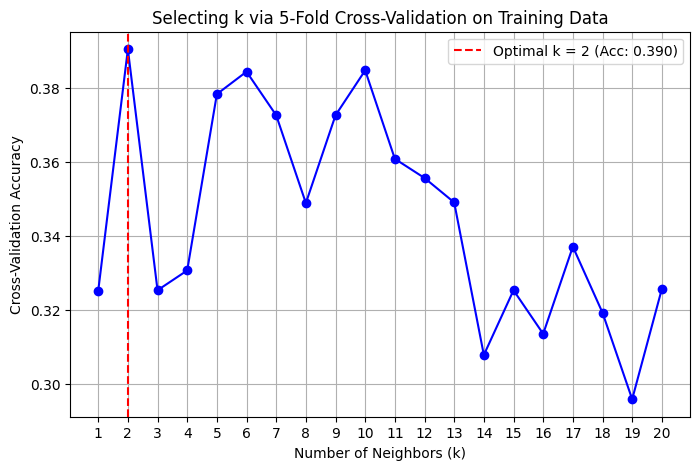

The optimal value for k selected via cross-validation is k = 2 with an validation accuracy of 0.3904.


In [7]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score
import numpy as np
k_values = list(range(1, 21))
cv_scores = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn, X_train, y_train, cv=5, scoring='accuracy')
    cv_scores.append(scores.mean())

best_k_idx = np.argmax(cv_scores)
best_k = k_values[best_k_idx]
best_score = cv_scores[best_k_idx]

plt.figure(figsize=(8, 5))
plt.plot(k_values, cv_scores, marker='o', linestyle='-', color='b')
plt.axvline(best_k, color='r', linestyle='--', label=f'Optimal k = {best_k} (Acc: {best_score:.3f})')
plt.xlabel('Number of Neighbors (k)')
plt.ylabel('Cross-Validation Accuracy')
plt.title('Selecting k via 5-Fold Cross-Validation on Training Data')
plt.xticks(k_values)
plt.legend()
plt.grid(True)
plt.show()

print(f"The optimal value for k selected via cross-validation is k = {best_k} with an validation accuracy of {best_score:.4f}.")

This is a 5-fold cross-validation classifier, it works by splitting the training data into 5 folds for each k value 1-20. It trains based on 4 and then measures the accuracy on the last remaining one. The 5 accuracies are then averaged and stored, which is what you see here on the splot.

Test Set Accuracy: 0.4379

--- Confusion Table ---
          Predicted 1  Predicted 2  Predicted 3  Predicted 4  Predicted 5
Actual 1           25            0            6            4            1
Actual 2            0           32            0            3            0
Actual 3           12            2            9            6            4
Actual 4           12            5            8            8            0
Actual 5           15            2           10            5            0

--- Detailed Classification Report ---
              precision    recall  f1-score   support

           1       0.39      0.69      0.50        36
           2       0.78      0.91      0.84        35
           3       0.27      0.27      0.27        33
           4       0.31      0.24      0.27        33
           5       0.00      0.00      0.00        32

    accuracy                           0.44       169
   macro avg       0.35      0.42      0.38       169
weighted avg       0.36      0.

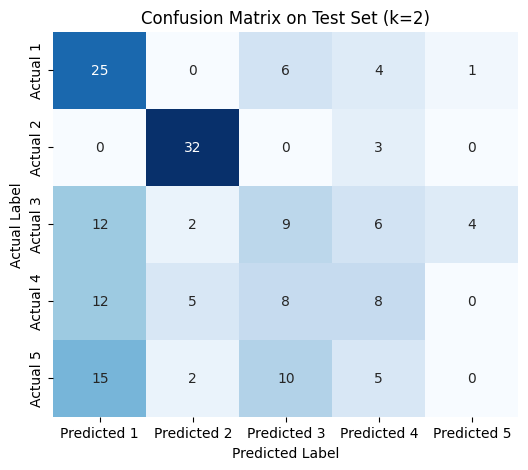

In [9]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

optimal_knn = KNeighborsClassifier(n_neighbors=2)
optimal_knn.fit(X_train, y_train)

y_pred = optimal_knn.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)

print(f"Test Set Accuracy: {accuracy:.4f}\n")

labels = sorted(y_test.unique())
conf_df = pd.DataFrame(conf_matrix, index=[f"Actual {i}" for i in labels], columns=[f"Predicted {i}" for i in labels])
print("--- Confusion Table ---")
print(conf_df)

print("\n--- Detailed Classification Report ---")
print(classification_report(y_test, y_pred))
#love me a good heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(conf_df, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix on Test Set (k=2)')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

The optimal k-NN model (k=2) achieved a relatively low overall test accuracy of 43.79%, struggling heavily to distinguish between most categories and failing completely to correctly identify any mines of Type 5. However, the model performed exceptionally well on Type 2 mines, achieving a 91% recall rate and 78% precision, showing that specific types can still be identified with high reliability.

Given the model's performance, folks using this should generally trust predictions for Type 2 mines since they exhibit high accuracy and recall. Conversely, any prediction of Type 1, 3, or 4 should be treated with extreme caution, as the model frequently confuses these categories. Most importantly, because the model completely fails to identify Type 5 mines (0% recall), any safety protocol must assume unidentified or ambiguous readings could be highly dangerous Type 5 mines.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]